# Hardware Performance Comparison Report

## 1. Objective

This notebook consolidates and analyzes inference benchmarking results
for a PyTorch-based Human Activity Recognition (HAR) CNN across three
hardware platforms:

- CPU (Local machine)
- NVIDIA Tesla T4 GPU (Google Colab)
- Google TPU v5e (Google Colab)

The objective is to compare inference latency, batch processing time,
throughput, and run-to-run variability under a consistent benchmark
protocol.

## 2. Benchmark Configuration

- Dataset: UCI Human Activity Recognition
- Test samples: 2,947
- Model: HAR_CNN
- Input shape: 6 channels × 128 time steps
- Batch size: 64
- Warm-up: One complete test dataset pass
- Measured runs: 3
- Execution mode: PyTorch inference mode

## Import libraries and load benchmark results

In [1]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Project paths
PROJECT_ROOT = Path.cwd().parent
RESULTS_DIR = PROJECT_ROOT / "results"

# Benchmark result files
cpu_file = RESULTS_DIR / "inference_benchmark_cpu_standardized.csv"
gpu_file = RESULTS_DIR / "inference_benchmark_gpu_standardized.csv"
tpu_file = RESULTS_DIR / "inference_benchmark_tpu_standardized.csv"

# Check that all files exist
for file in [cpu_file, gpu_file, tpu_file]:
    print(file.name, ":", file.exists())

# Load results
cpu_df = pd.read_csv(cpu_file)
gpu_df = pd.read_csv(gpu_file)
tpu_df = pd.read_csv(tpu_file)

print("\nAll benchmark files loaded successfully.")

inference_benchmark_cpu_standardized.csv : True
inference_benchmark_gpu_standardized.csv : True
inference_benchmark_tpu_standardized.csv : True

All benchmark files loaded successfully.


## Combine the results

In [2]:
# Combine all hardware results
comparison_df = pd.concat(
    [cpu_df, gpu_df, tpu_df],
    ignore_index=True
)

# Select relevant columns
comparison_df = comparison_df[
    [
        "device",
        "hardware",
        "average_time_seconds",
        "median_time_seconds",
        "std_time_seconds",
        "average_batch_time_ms",
        "throughput_samples_per_second",
        "test_samples",
        "batch_size",
        "warmup_passes",
        "benchmark_runs"
    ]
]

display(comparison_df)

,device,hardware,average_time_seconds,median_time_seconds,std_time_seconds,average_batch_time_ms,throughput_samples_per_second,test_samples,batch_size,warmup_passes,benchmark_runs
0,CPU,Local CPU,0.096353,0.097061,0.001801,2.050070,30585.356180,2947,64,1,3
1,GPU,Tesla T4,0.049338,0.046847,0.005487,1.049743,59730.933124,2947,64,1,3
2,TPU,Google TPU v5e,0.078957,0.078872,0.001391,1.679944,37323.944209,2947,64,1,3


## Validate experimental consistency

In [3]:
# Verify that all benchmarks used the same configuration
assert comparison_df["test_samples"].nunique() == 1
assert comparison_df["batch_size"].nunique() == 1
assert comparison_df["warmup_passes"].nunique() == 1
assert comparison_df["benchmark_runs"].nunique() == 1

assert len(comparison_df) == 3

print("Benchmark validation successful!")
print("Test samples:", comparison_df["test_samples"].iloc[0])
print("Batch size:", comparison_df["batch_size"].iloc[0])
print("Warm-up passes:", comparison_df["warmup_passes"].iloc[0])
print("Measured runs:", comparison_df["benchmark_runs"].iloc[0])

Benchmark validation successful!
Test samples: 2947
Batch size: 64
Warm-up passes: 1
Measured runs: 3


## 3. Relative Performance Analysis

The local CPU is used as the baseline hardware.

Speedup is calculated as the CPU throughput divided by the
throughput of the other hardware platform.

A speedup greater than 1 indicates higher throughput than the CPU.

In [4]:
# Get CPU throughput as baseline
cpu_throughput = comparison_df.loc[
    comparison_df["device"] == "CPU",
    "throughput_samples_per_second"
].iloc[0]

# Calculate speedup relative to CPU
comparison_df["speedup_vs_cpu"] = (
    comparison_df["throughput_samples_per_second"] / cpu_throughput
)

# Calculate throughput improvement percentage
comparison_df["throughput_improvement_percent"] = (
    (comparison_df["speedup_vs_cpu"] - 1) * 100
)

display(
    comparison_df[
        [
            "device",
            "hardware",
            "throughput_samples_per_second",
            "speedup_vs_cpu",
            "throughput_improvement_percent"
        ]
    ].round(3)
)

,device,hardware,throughput_samples_per_second,speedup_vs_cpu,throughput_improvement_percent
0,CPU,Local CPU,30585.356,1.000,0.000
1,GPU,Tesla T4,59730.933,1.953,95.293
2,TPU,Google TPU v5e,37323.944,1.220,22.032


## 4. Hardware Performance Visualization

### 4.1 Inference Throughput

This chart compares the number of test samples processed per second
by each hardware platform. Higher throughput indicates better
inference performance.

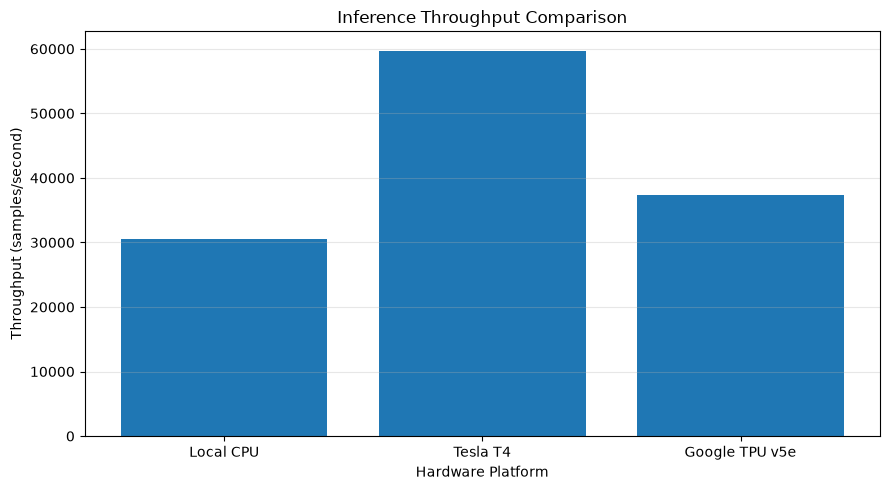

In [5]:
plt.figure(figsize=(9, 5))

plt.bar(
    comparison_df["hardware"],
    comparison_df["throughput_samples_per_second"]
)

plt.title("Inference Throughput Comparison")
plt.xlabel("Hardware Platform")
plt.ylabel("Throughput (samples/second)")
plt.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()

### 4.2 Average Inference Time

This chart compares the total time required to process all 2,947
test samples. Lower inference time indicates better performance.

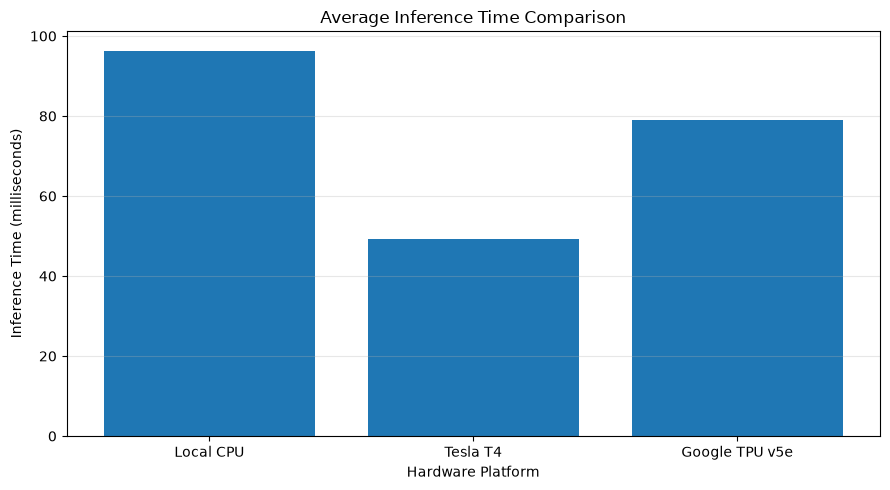

In [6]:
plt.figure(figsize=(9, 5))

plt.bar(
    comparison_df["hardware"],
    comparison_df["average_time_seconds"] * 1000
)

plt.title("Average Inference Time Comparison")
plt.xlabel("Hardware Platform")
plt.ylabel("Inference Time (milliseconds)")
plt.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()

### 4.3 Run-to-Run Variability

This comparison uses the standard deviation of the three measured
inference runs.

A lower standard deviation indicates more consistent execution
times across the measured runs.

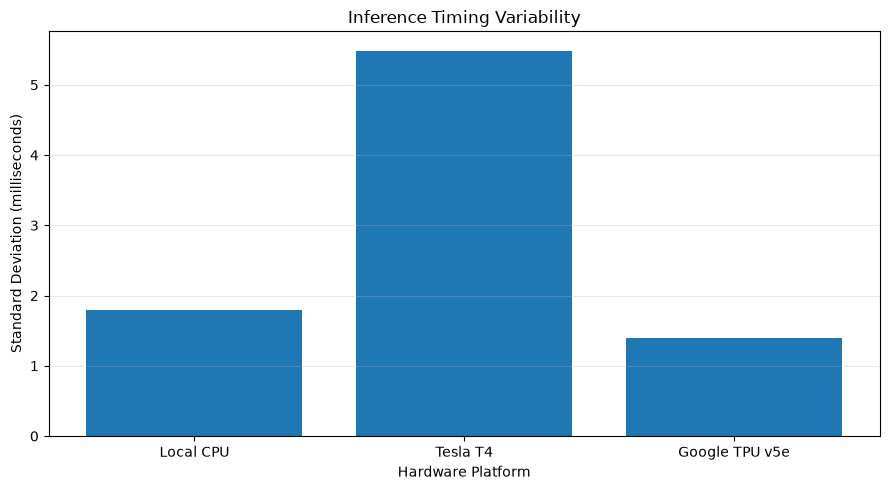

In [7]:
plt.figure(figsize=(9, 5))

plt.bar(
    comparison_df["hardware"],
    comparison_df["std_time_seconds"] * 1000
)

plt.title("Inference Timing Variability")
plt.xlabel("Hardware Platform")
plt.ylabel("Standard Deviation (milliseconds)")
plt.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()

## 5. Consolidated Benchmark Results

The benchmark results from all three hardware platforms are
combined into a single CSV file for reproducibility and further analysis.

In [8]:
# Save consolidated results
comparison_file = RESULTS_DIR / "hardware_comparison.csv"

comparison_df.to_csv(
    comparison_file,
    index=False
)

print("Comparison results saved to:", comparison_file)

display(comparison_df.round(4))

Comparison results saved to: d:\sensor-har-pytorch-accelerators\results\hardware_comparison.csv


,device,hardware,average_time_seconds,median_time_seconds,std_time_seconds,average_batch_time_ms,throughput_samples_per_second,test_samples,batch_size,warmup_passes,benchmark_runs,speedup_vs_cpu,throughput_improvement_percent
0,CPU,Local CPU,0.0964,0.0971,0.0018,2.0501,30585.3562,2947,64,1,3,1.0000,0.0000
1,GPU,Tesla T4,0.0493,0.0468,0.0055,1.0497,59730.9331,2947,64,1,3,1.9529,95.2926
2,TPU,Google TPU v5e,0.0790,0.0789,0.0014,1.6799,37323.9442,2947,64,1,3,1.2203,22.0321
